# 02 — Аналіз baseline A (DETR-R50 з COCO)

Ноутбук лише читає `runs/<name>/` (`metrics.csv`, `metrics_{val,test}.json`, `predictions_*.json`, `config.yaml`) і викликає функції з `malaria_ssl.eval.viz`. Пороги F1 обрано на val і без змін застосовано до test.

Метрики створюються командами:
```
python scripts/evaluate.py runs/<name> --split val --bootstrap
python scripts/evaluate.py runs/<name> --split test --bootstrap
```

In [1]:
import pandas as pd

from malaria_ssl.eval import viz
from malaria_ssl.utils.config import resolve_path

RUN_NAMES = ['a_coco_detr_binary', 'a_coco_detr_multiclass', 'a_scratch_r50_binary']
FALLBACK = ['dry_b_2epochs']  # 2-epoch dry run, used only until the full runs exist

names = [n for n in RUN_NAMES if (resolve_path('runs') / n / 'metrics.csv').exists()]
if not names:
    print('Full runs not found -> showing the dry run', FALLBACK)
    names = FALLBACK
runs = [viz.load_run(resolve_path('runs') / n) for n in names]
MAIN = runs[0]
[(r['name'], list(r['metrics'])) for r in runs]

C:\Users\Alex\miniconda3\envs\medthesis\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Full runs not found -> showing the dry run ['dry_b_2epochs']


[('dry_b_2epochs', ['val'])]

## Криві навчання

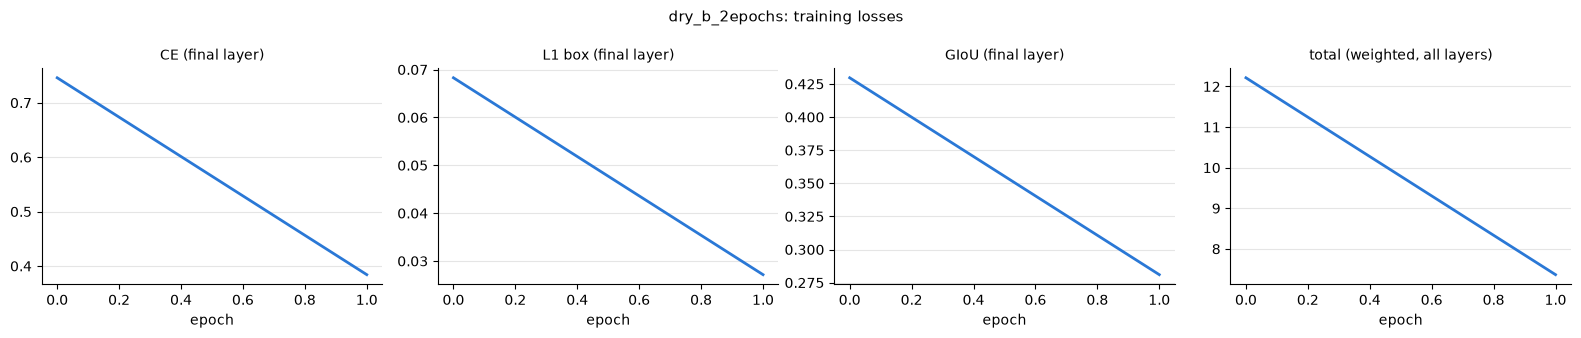

In [2]:
for r in runs:
    viz.plot_training_curves(r)

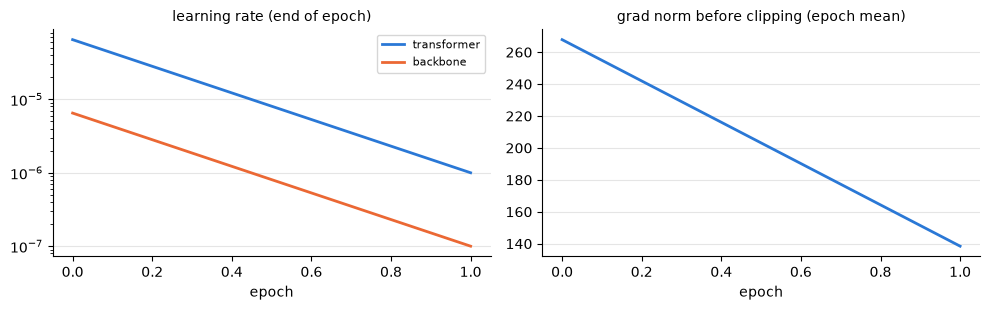

In [3]:
viz.plot_lr_gradnorm(MAIN);

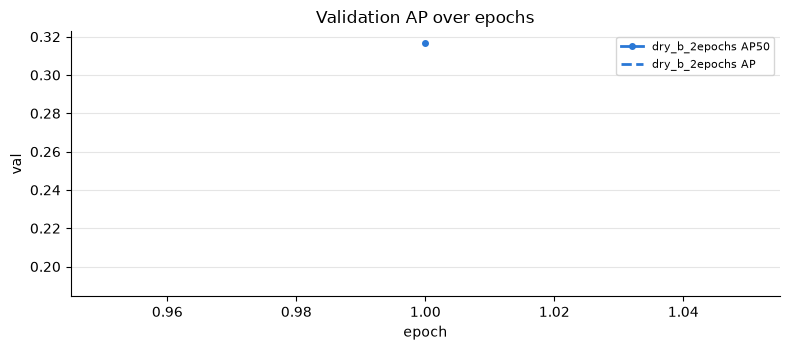

In [4]:
viz.plot_val_ap(runs);

## Val vs test

In [5]:
pd.set_option('display.float_format', '{:.4f}'.format)
viz.metrics_table(runs)

,run,split,label_mode,epoch,AP,AP50,AP75,AR@300,macro_F1,AP50_CI95,macro_F1_CI95
0,dry_b_2epochs,val,binary,1,0.1907,0.3165,0.2125,0.3131,0.3403,"[0.303, 0.335]","[0.330, 0.351]"


In [6]:
for r in runs:
    display(viz.per_class_table(r).assign(run=r['name']))

,split,class,n_gt,AP,AP50,AR@300,P,R,F1,thr,AP50_CI95,F1_CI95,run
0,val,uninfected,12033,0.3813,0.6330,0.6242,0.6165,0.7425,0.6737,0.9067,"[0.606, 0.669]","[0.656, 0.695]",dry_b_2epochs
1,val,infected,298,0.0000,0.0001,0.0020,0.0070,0.0067,0.0068,0.0140,"[0.000, 0.000]","[0.000, 0.016]",dry_b_2epochs


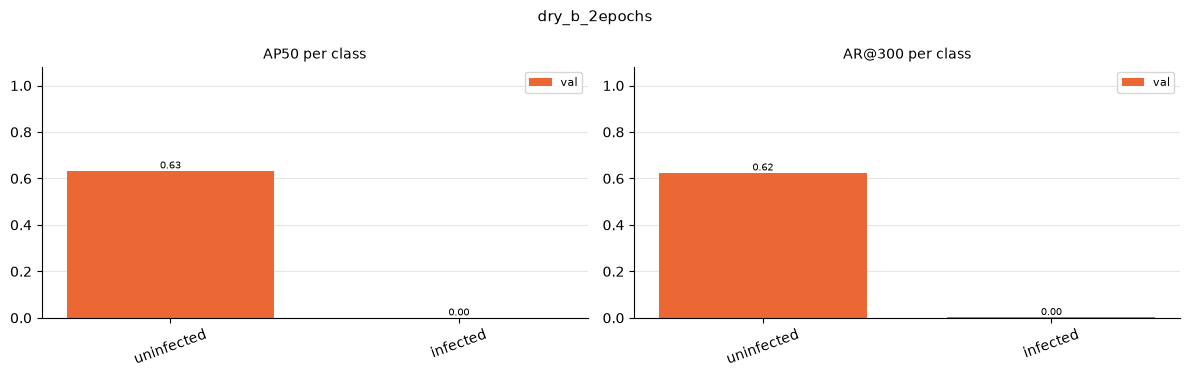

In [7]:
for r in runs:
    viz.plot_per_class(r)

## Матриця плутанини та PR-криві

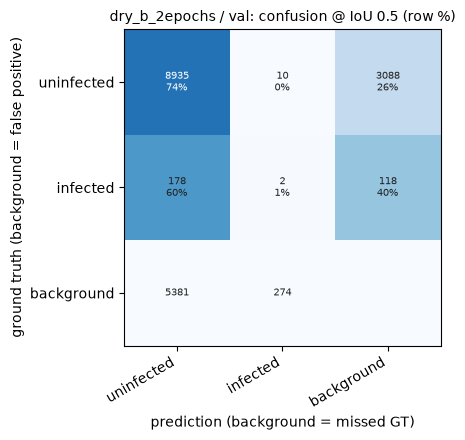

In [8]:
for r in runs:
    for s, m in r['metrics'].items():
        viz.plot_confusion(m, f"{r['name']} / {s}: confusion @ IoU 0.5 (row %)")

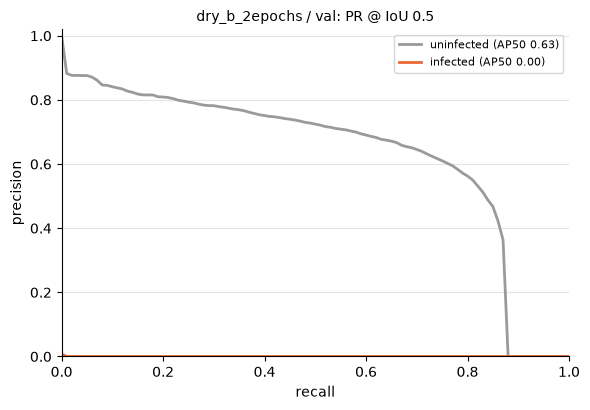

In [9]:
for r in runs:
    for s, m in r['metrics'].items():
        viz.plot_pr_curves(m, f"{r['name']} / {s}: PR @ IoU 0.5")

## AP за кількістю клітин на зображенні

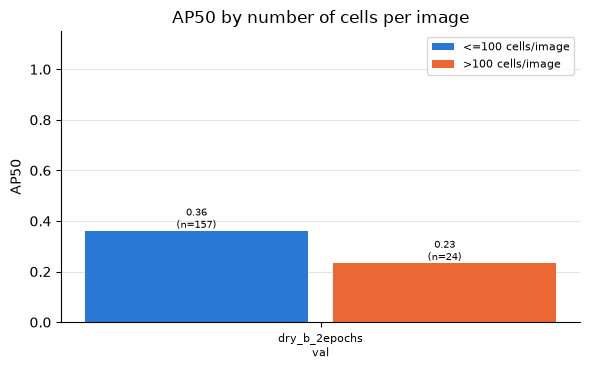

In [10]:
viz.plot_ap_by_density(runs);

## Приклади: GT vs передбачення

Спочатку зображення з пропущеними клітинами рідкісних класів, потім із хибнопозитивними, решта — випадкові.

examples from dry_b_2epochs val


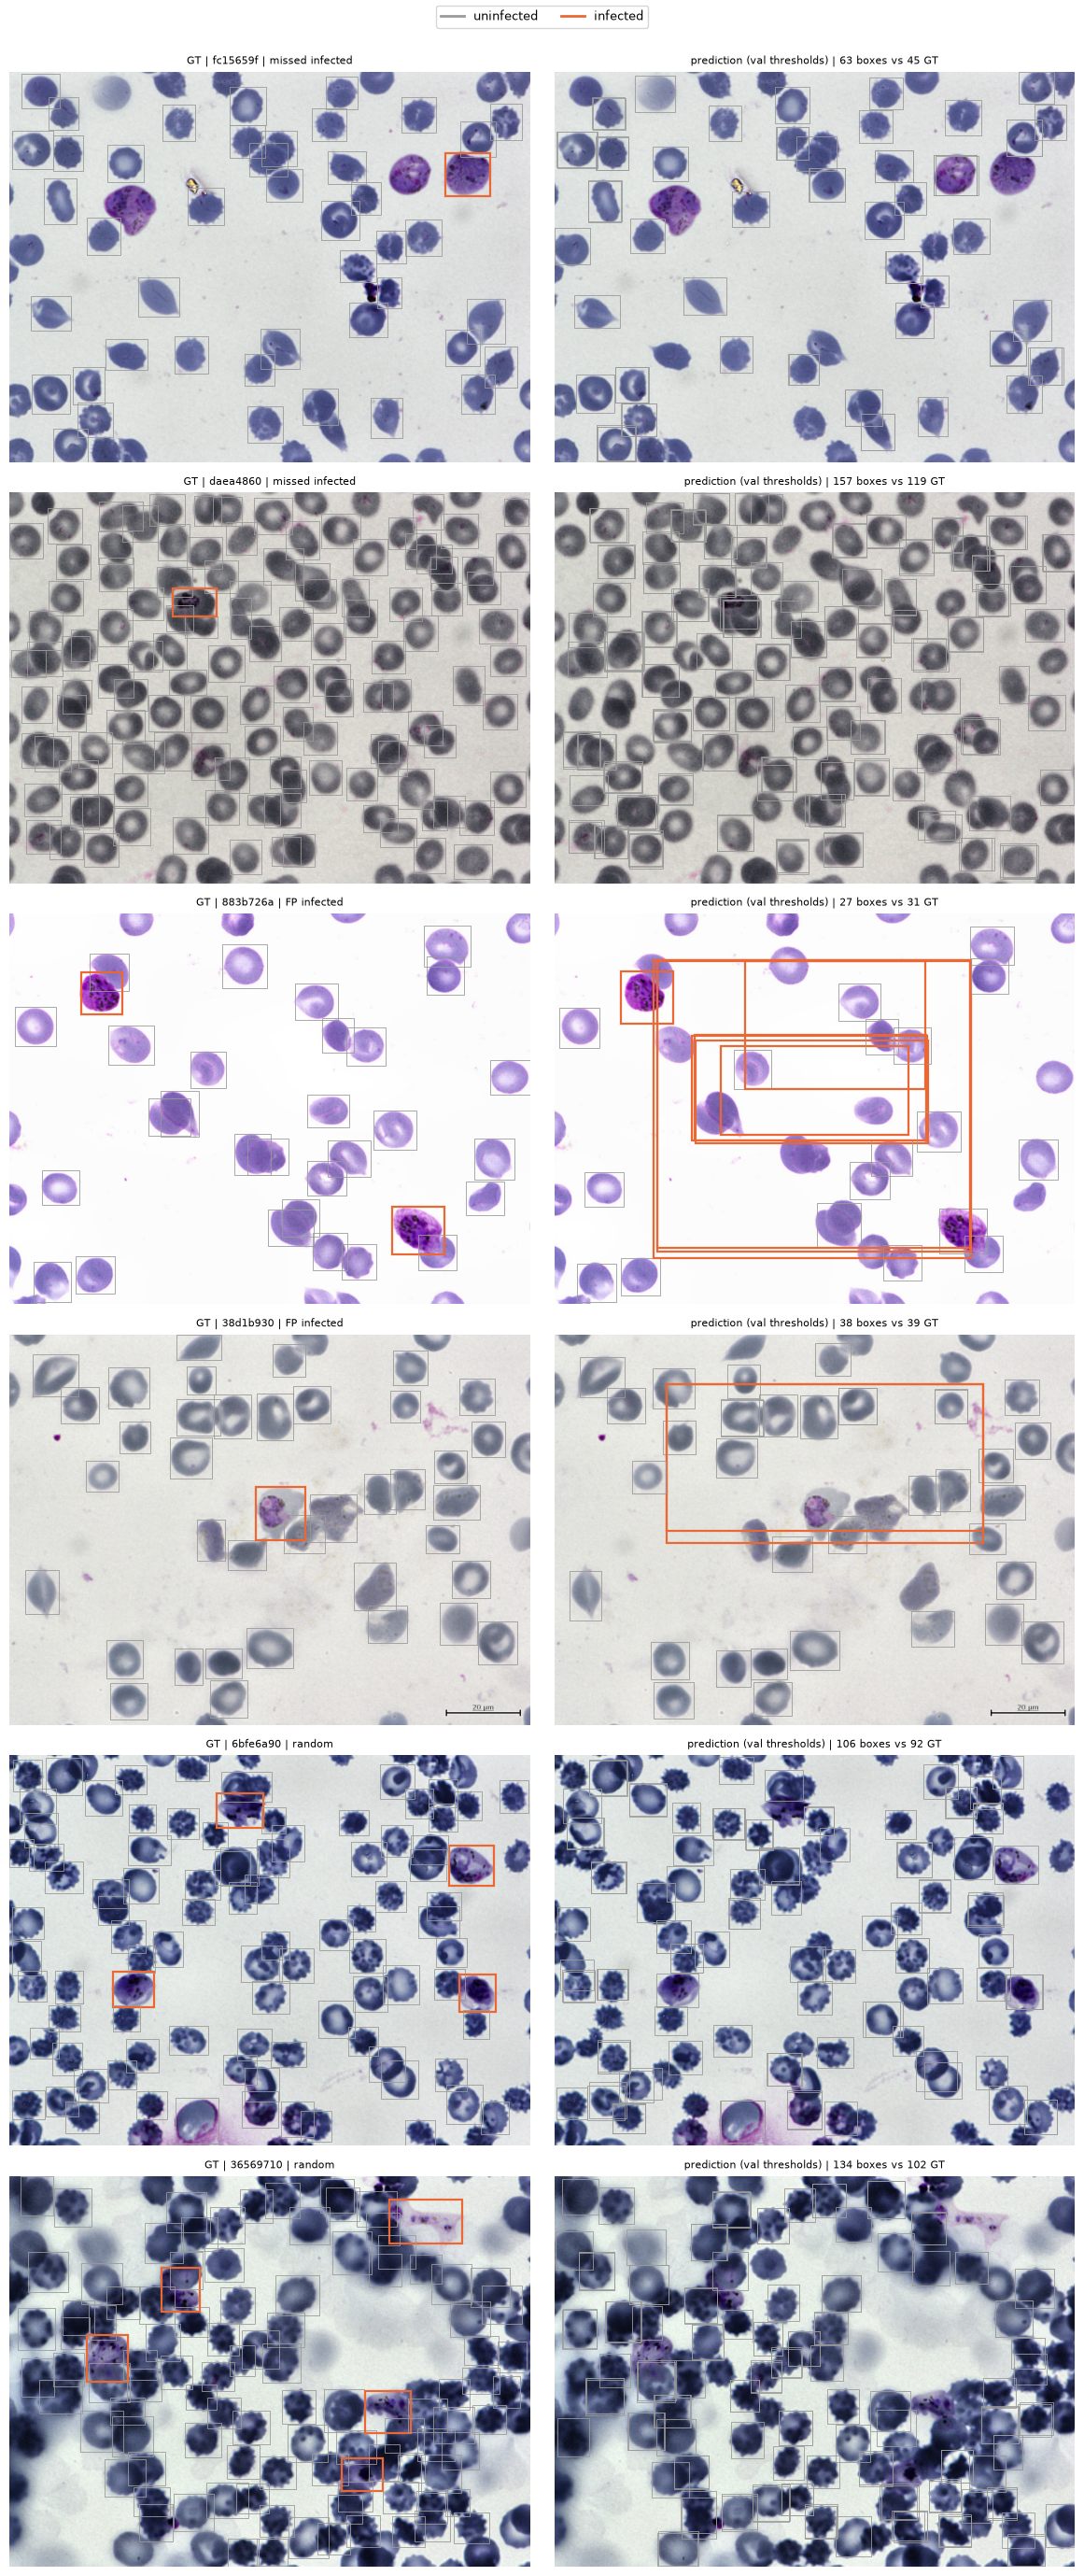

In [11]:
split = 'test' if 'test' in MAIN['predictions'] else 'val'
print('examples from', MAIN['name'], split)
viz.plot_examples(MAIN, split, n=6, seed=MAIN['config']['seed']);